В цьому ноутбуці відбуваєтся тестування рандомних активів на рандомному проміжку часу. Метою є візуальна перевірка коректність роботи бектест алгоритму

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import random
import yaml

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_stocks.csv", index_col=0, parse_dates=True)
df_stocks.dropna(how='all', inplace=True, axis=1)
df_stocks.dropna(how='all', inplace=True, axis=0)
df_stocks

,AAPL,MSFT,NVDA,AMZN,GOOG,GOOGL,META,BRK-B,TSLA,AVGO,...,CS.PA,BNP.PA,SAF.PA,CAP.PA,DTE.DE,BAS.DE,IFX.DE,BAYN.DE,NOKIA.HE,VOLV-B.ST
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-03,0.999442,58.281250,0.097526,4.468750,NaN,NaN,NaN,35.299999,NaN,NaN,...,32.639271,45.771416,46.004002,255.899994,71.000000,25.600000,NaN,46.350876,47.450001,43.500000
2000-01-04,0.915179,56.312500,0.094922,4.096875,NaN,NaN,NaN,34.080002,NaN,NaN,...,31.439299,44.484867,44.001999,237.199997,69.500000,24.875000,NaN,44.481094,43.362499,42.500000
2000-01-05,0.928571,56.906250,0.091797,3.487500,NaN,NaN,NaN,34.639999,NaN,NaN,...,30.959311,43.544697,40.698002,213.800003,67.000000,23.924999,NaN,43.300182,39.502499,42.500000
2000-01-06,0.848214,55.000000,0.085807,3.278125,NaN,NaN,NaN,36.080002,NaN,NaN,...,30.719315,42.060219,42.237999,215.199997,61.000000,24.014999,NaN,43.447796,39.502499,42.500000
2000-01-07,0.888393,55.718750,0.087240,3.478125,NaN,NaN,NaN,36.400002,NaN,NaN,...,31.679295,42.604527,43.330002,226.000000,64.739998,25.000000,NaN,45.258530,41.625000,42.700001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-06-08,301.540009,411.739990,208.639999,245.220001,361.170013,363.309998,585.390015,487.000000,408.950012,396.600006,...,39.700001,93.150002,294.500000,102.400002,27.629999,48.849998,78.239998,35.689999,12.965000,323.600006
2026-06-09,290.549988,403.410004,208.190002,244.190002,362.290009,364.260010,584.590027,487.769989,396.679993,392.160004,...,40.169998,93.389999,295.600006,100.500000,27.780001,48.525002,75.660004,35.490002,12.040000,318.899994
2026-06-10,291.579987,397.359985,200.419998,238.000000,353.320007,356.380005,570.979980,483.679993,381.589996,372.100006,...,40.529999,91.959999,291.500000,99.599998,28.629999,47.980000,75.099998,35.369999,11.945000,306.000000


In [4]:
sequence_length = 365 * 3

start = random.randint(0, len(df_stocks) - sequence_length)
prices = df_stocks.iloc[start:start + sequence_length]
prices.index.min(), prices.index.max()

(Timestamp('2018-02-02 00:00:00'), Timestamp('2022-06-08 00:00:00'))

In [5]:
token_num = 10

random_token = random.sample(df_stocks.columns.tolist(), token_num)
random_token

['DIS',
 'MSFT',
 'AI.PA',
 'AD.AS',
 'BAS.DE',
 'BRK-B',
 'NOVO-B.CO',
 'AIR.PA',
 'CRM',
 'CAP.PA']

In [6]:
# strategy={"minimum_profit": 1.5, "cooldown_long": 30.0, "cooldown_short": 7.0}
strategy={}

18:00:03 - cmdstanpy - INFO - Chain [1] start processing
18:00:03 - cmdstanpy - INFO - Chain [1] done processing


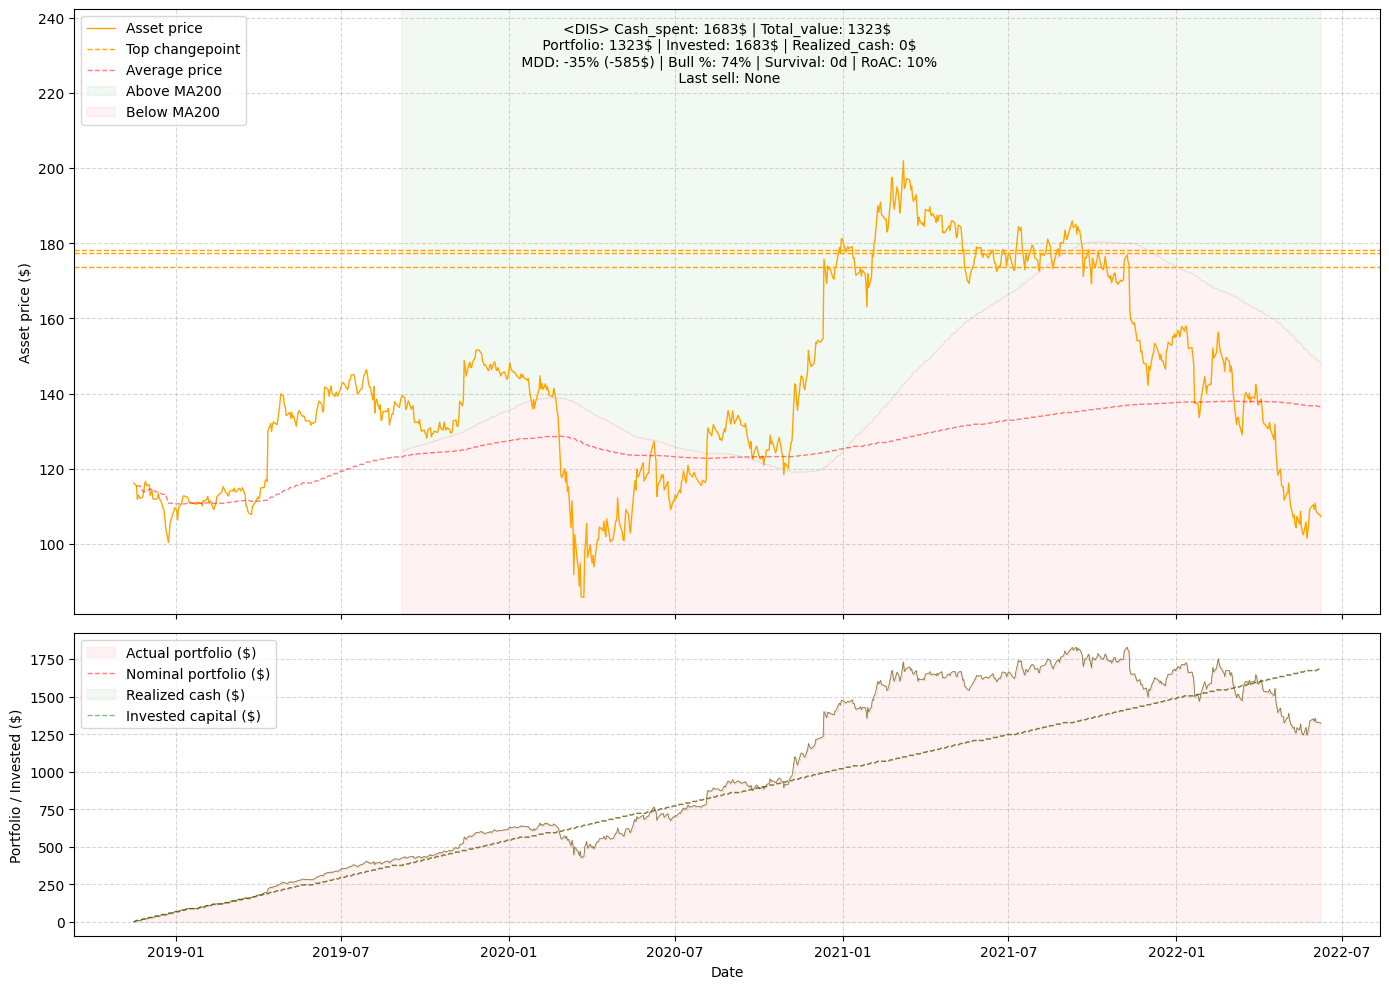

18:00:04 - cmdstanpy - INFO - Chain [1] start processing
18:00:04 - cmdstanpy - INFO - Chain [1] done processing


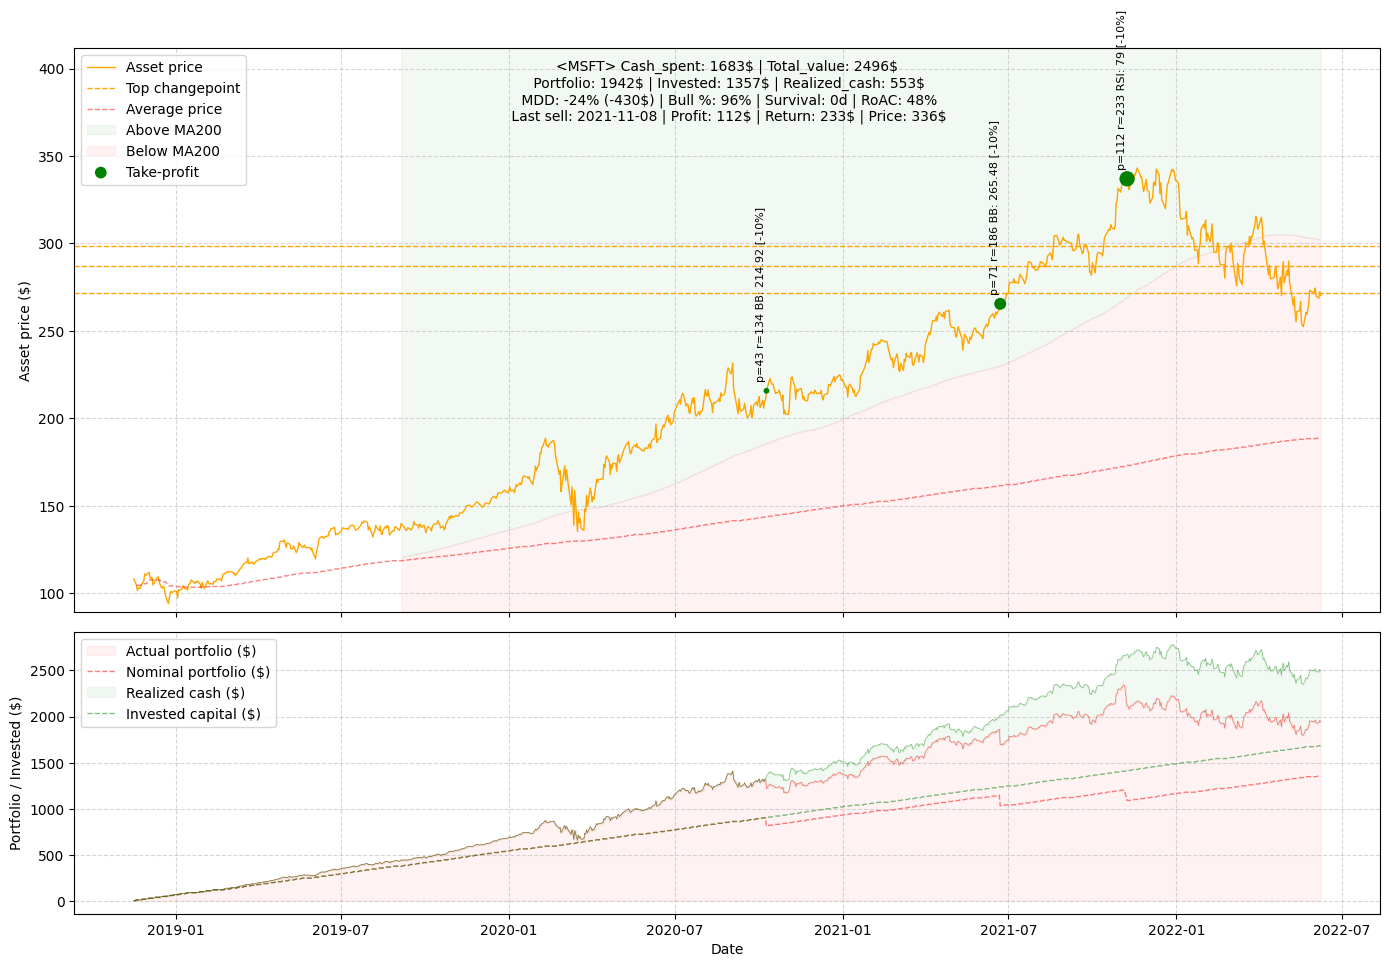

18:00:04 - cmdstanpy - INFO - Chain [1] start processing
18:00:04 - cmdstanpy - INFO - Chain [1] done processing


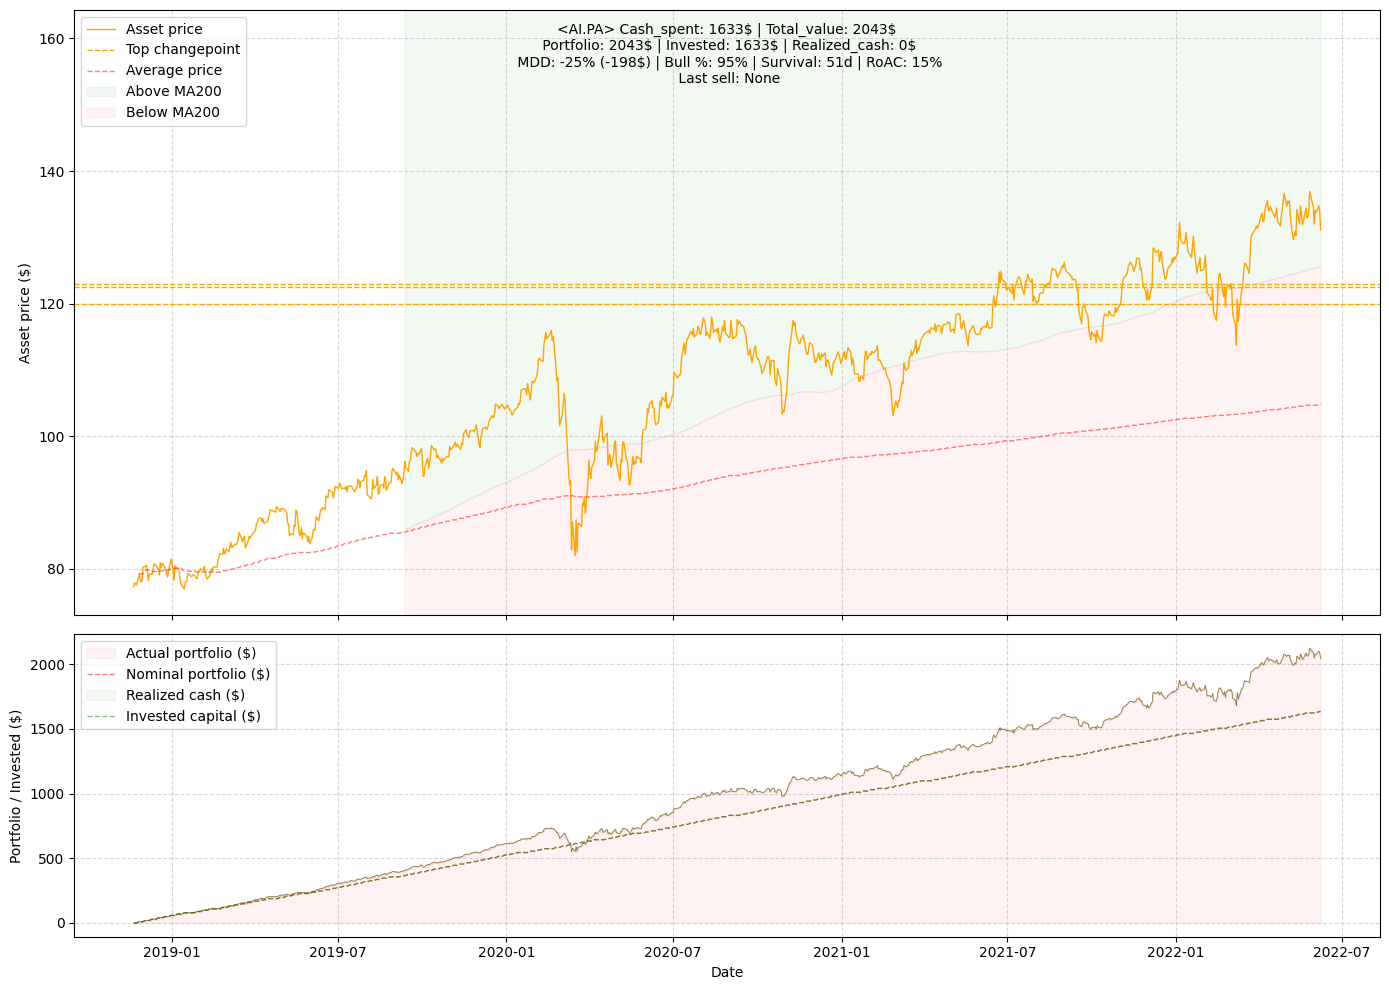

18:00:05 - cmdstanpy - INFO - Chain [1] start processing
18:00:05 - cmdstanpy - INFO - Chain [1] done processing


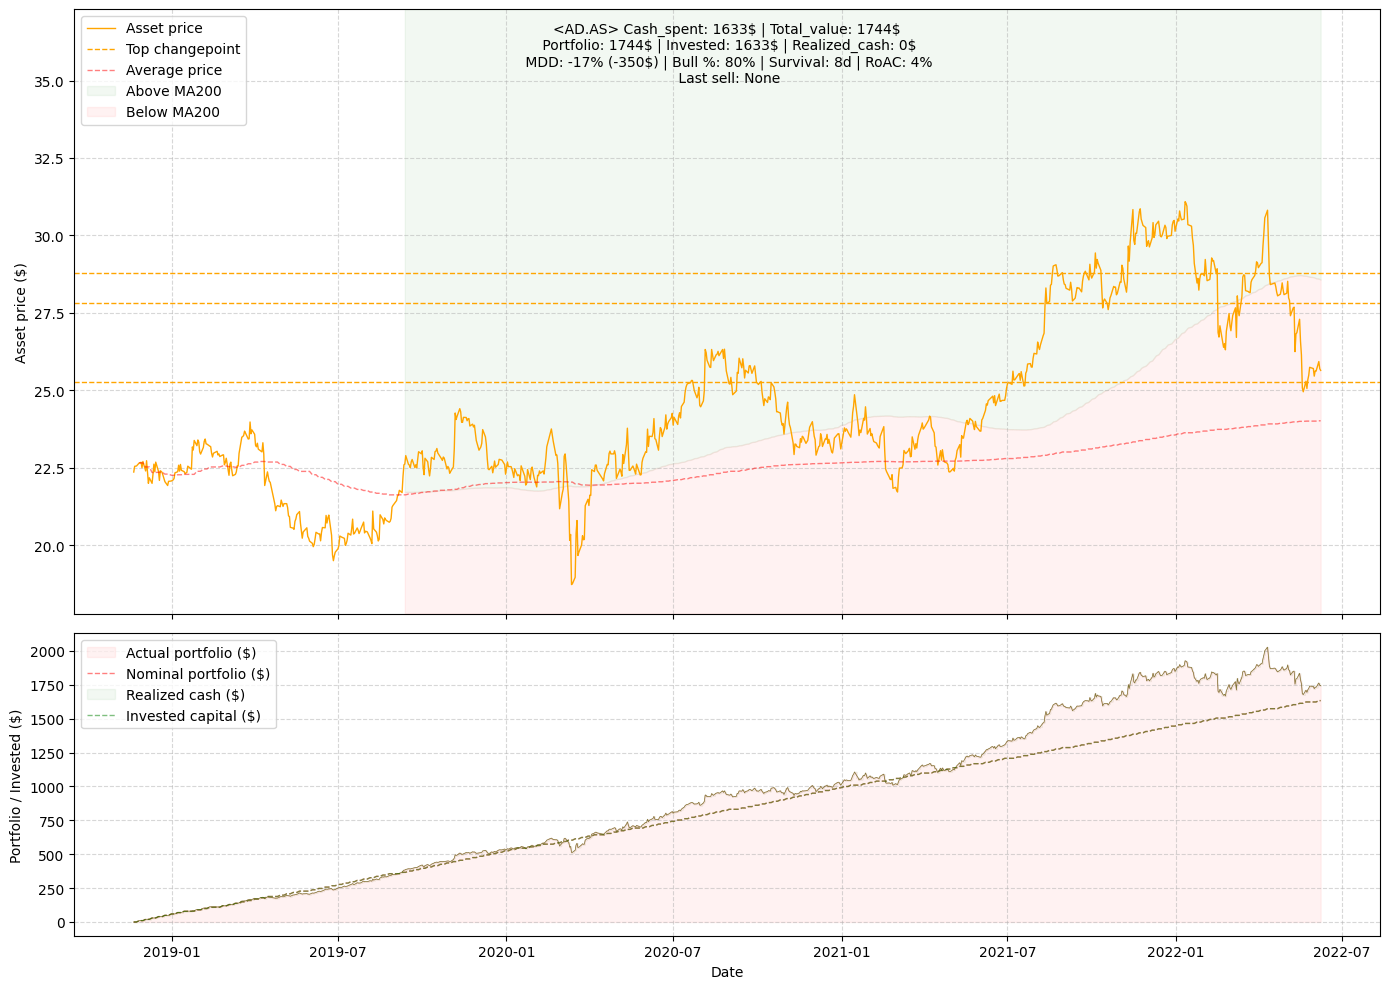

18:00:05 - cmdstanpy - INFO - Chain [1] start processing
18:00:05 - cmdstanpy - INFO - Chain [1] done processing


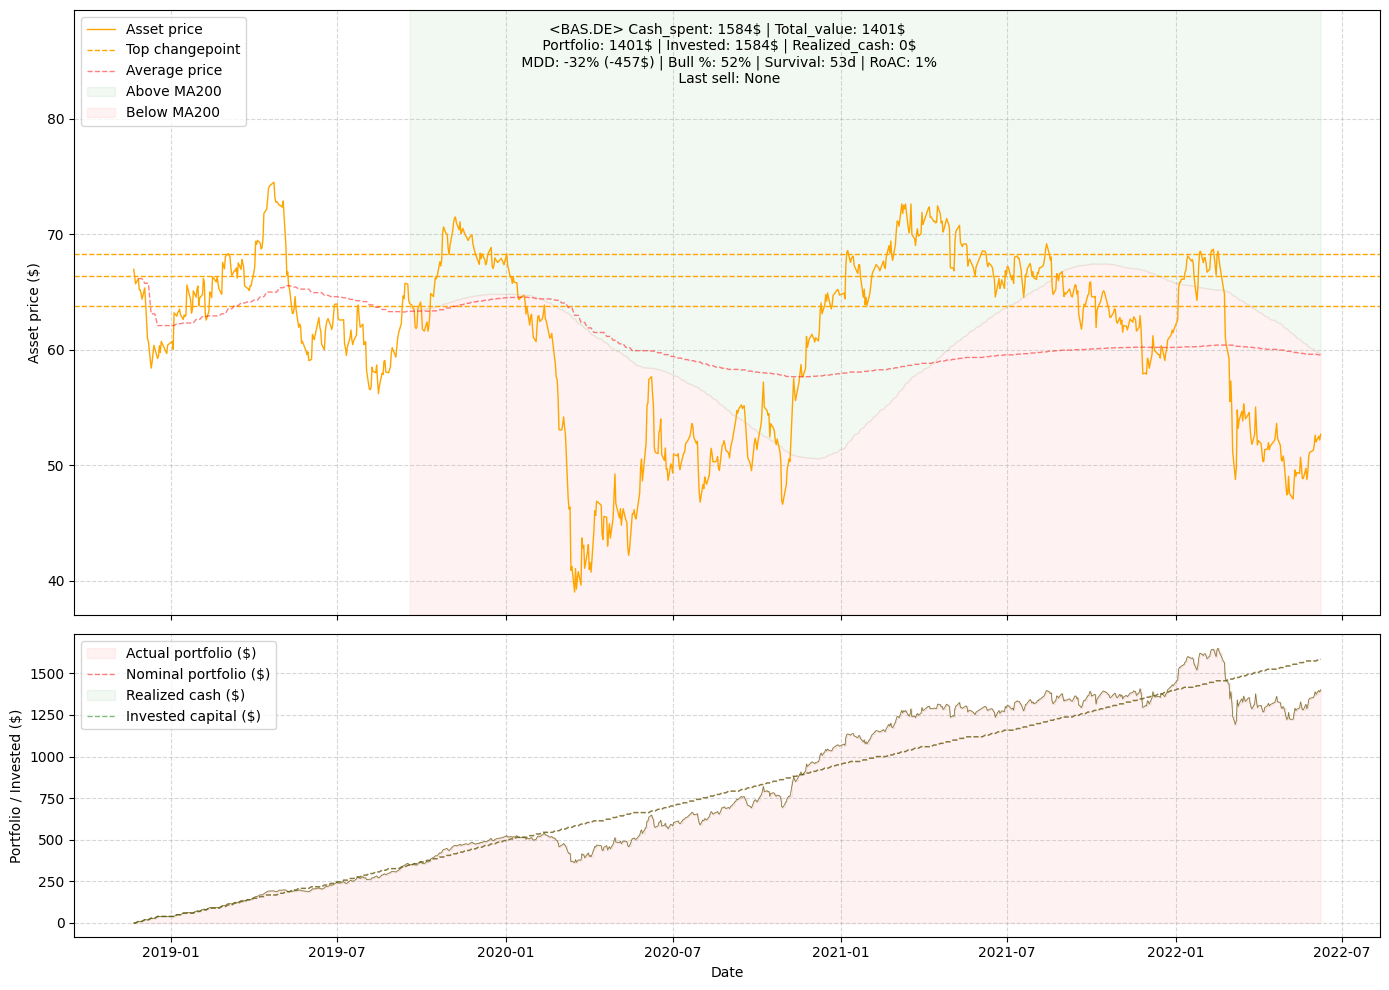

18:00:06 - cmdstanpy - INFO - Chain [1] start processing
18:00:06 - cmdstanpy - INFO - Chain [1] done processing


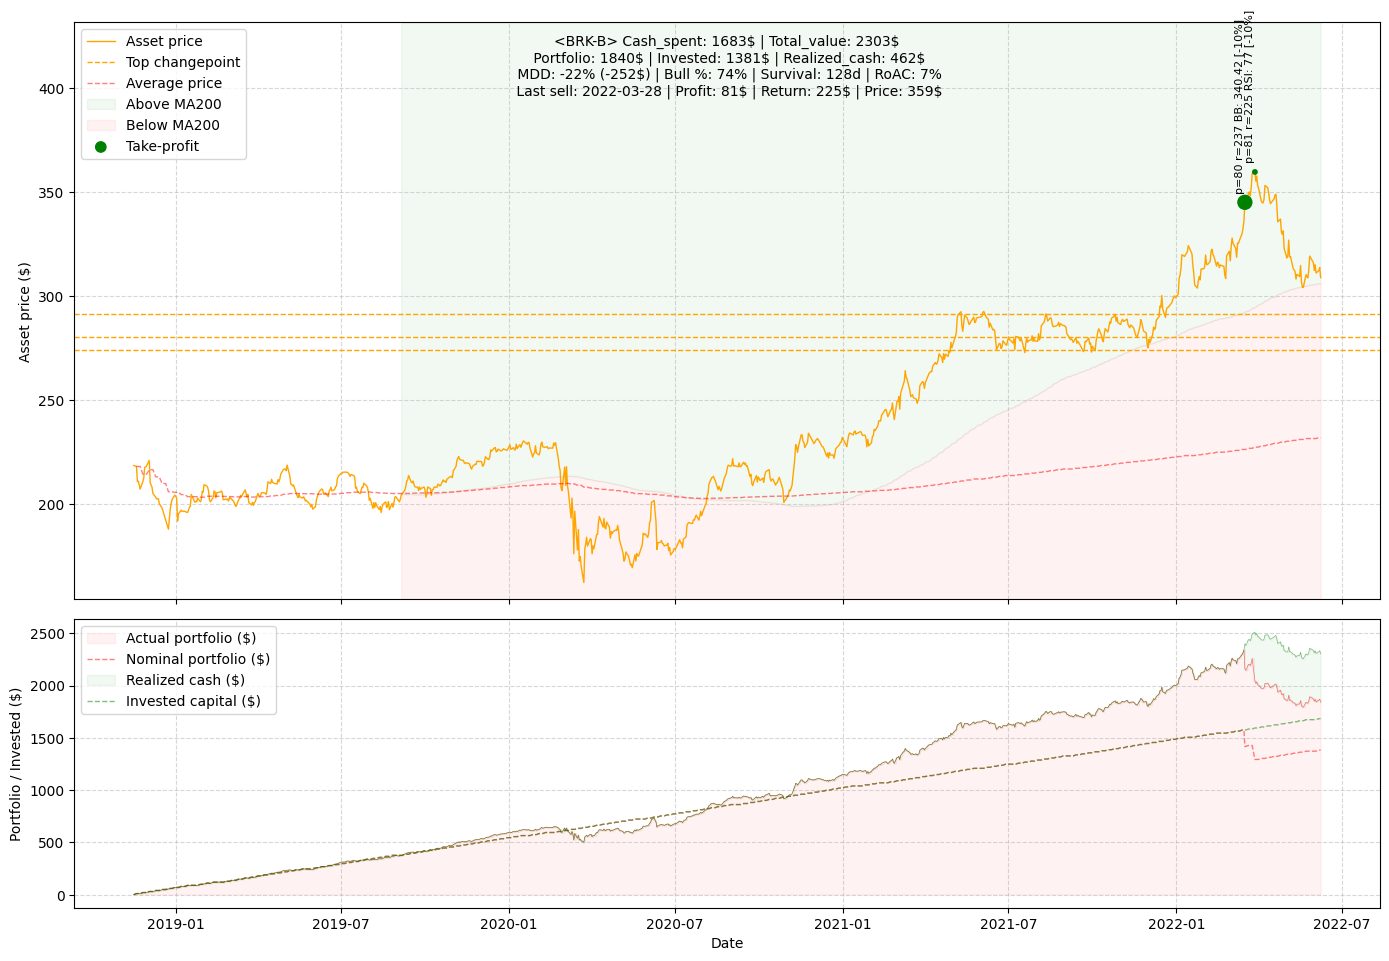

18:00:06 - cmdstanpy - INFO - Chain [1] start processing
18:00:07 - cmdstanpy - INFO - Chain [1] done processing


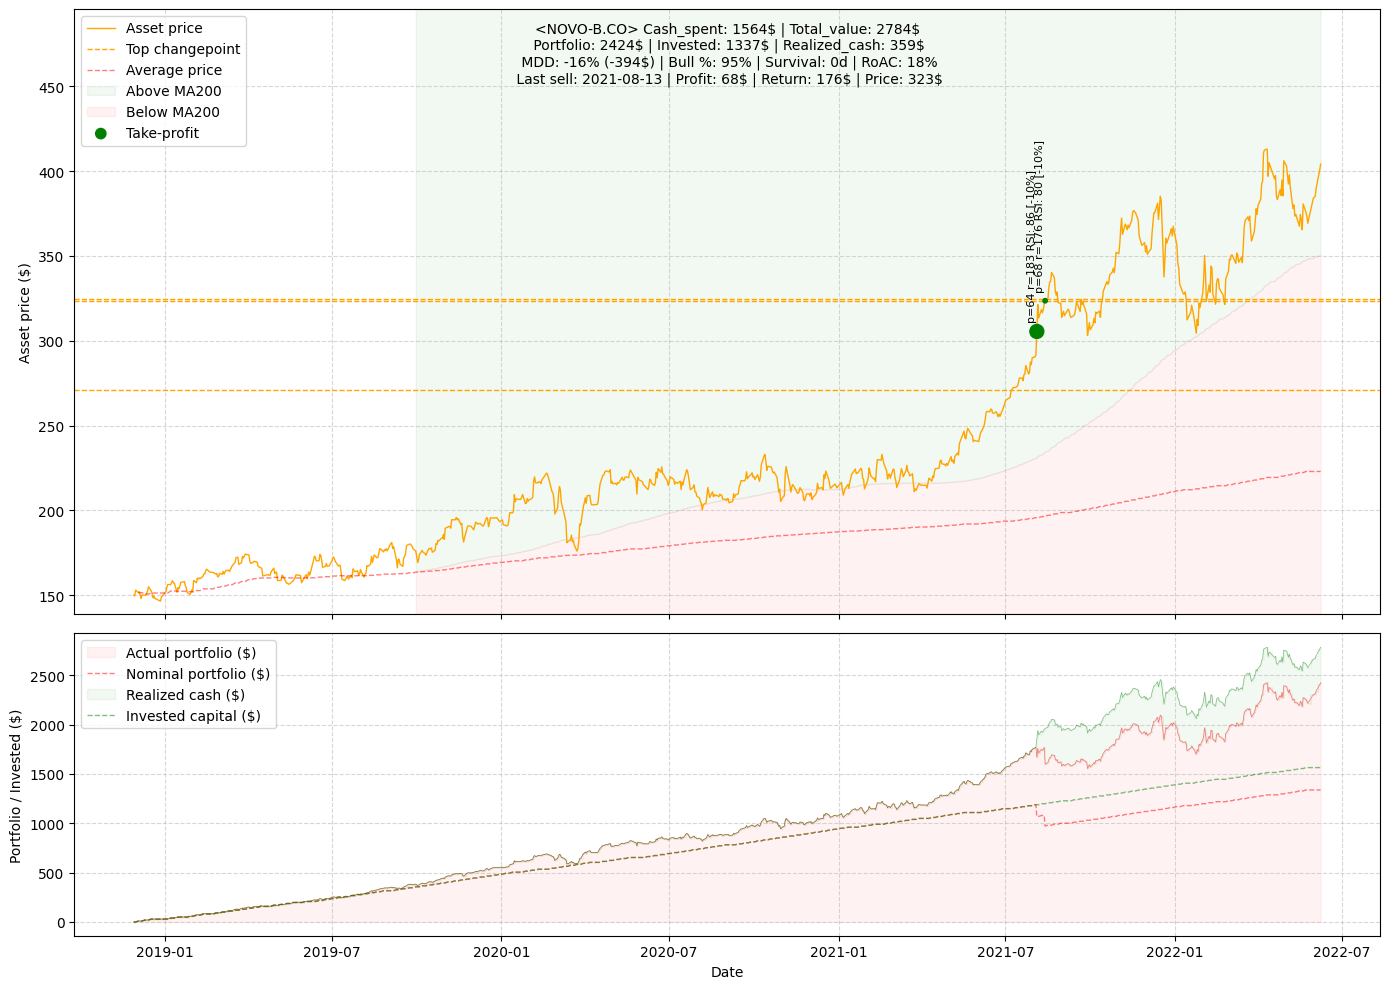

18:00:07 - cmdstanpy - INFO - Chain [1] start processing
18:00:07 - cmdstanpy - INFO - Chain [1] done processing


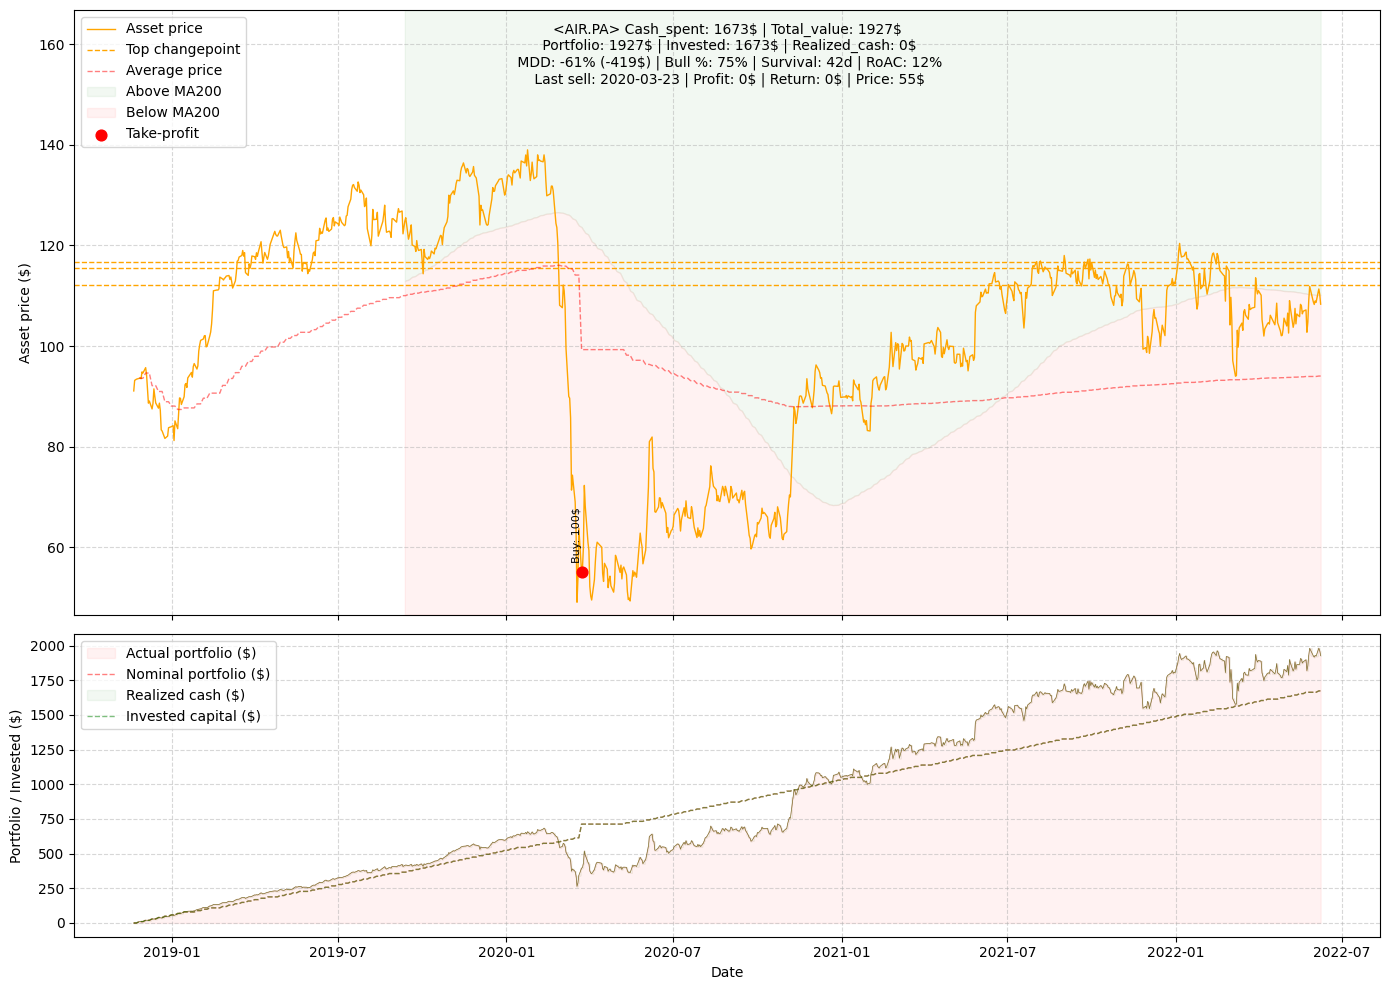

18:00:07 - cmdstanpy - INFO - Chain [1] start processing
18:00:08 - cmdstanpy - INFO - Chain [1] done processing


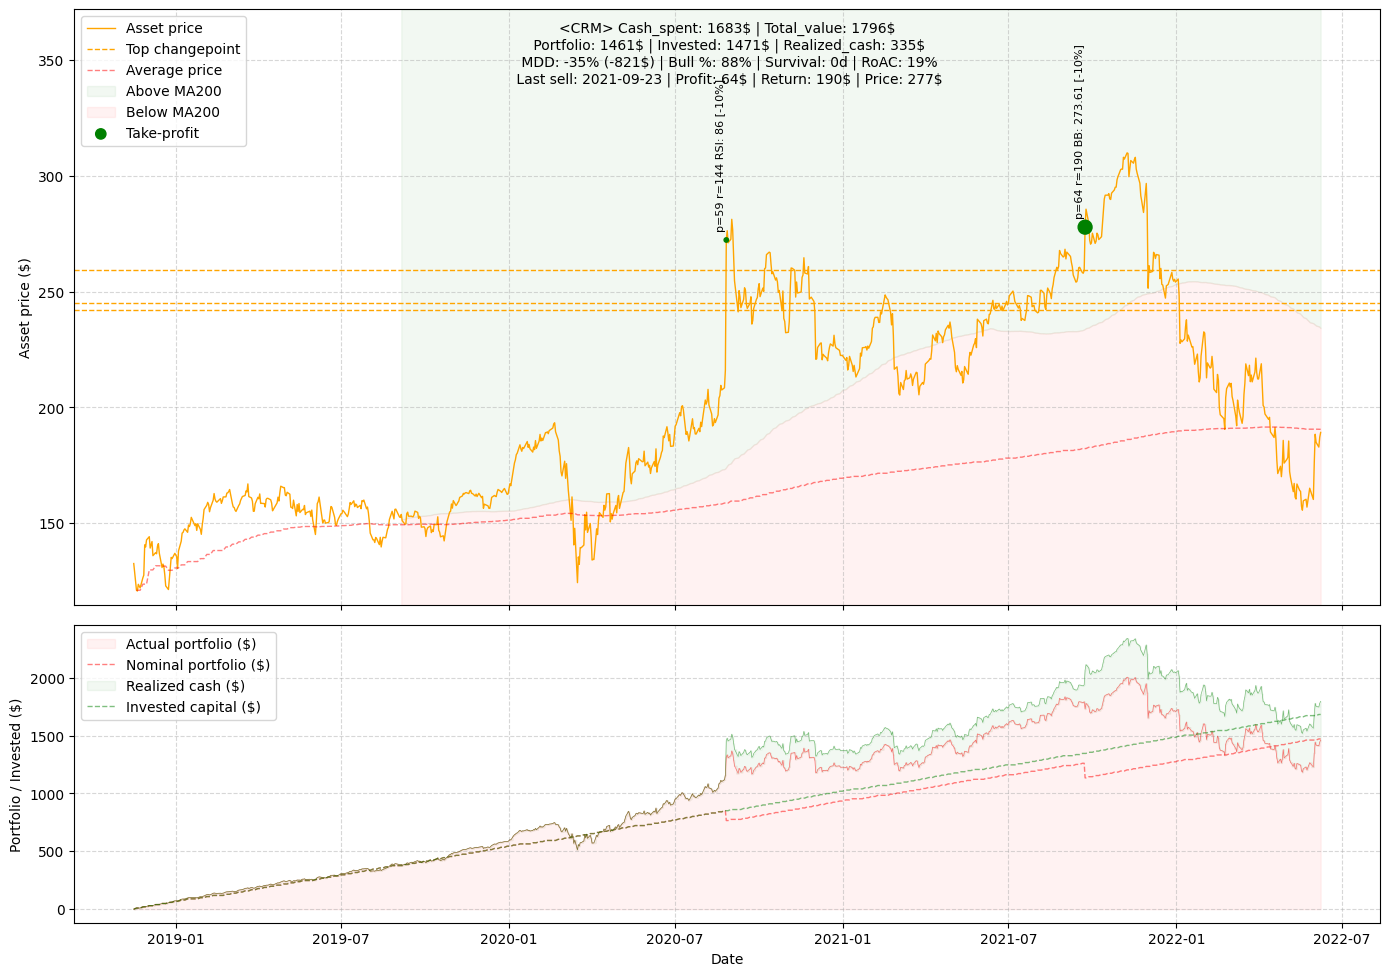

18:00:08 - cmdstanpy - INFO - Chain [1] start processing
18:00:08 - cmdstanpy - INFO - Chain [1] done processing


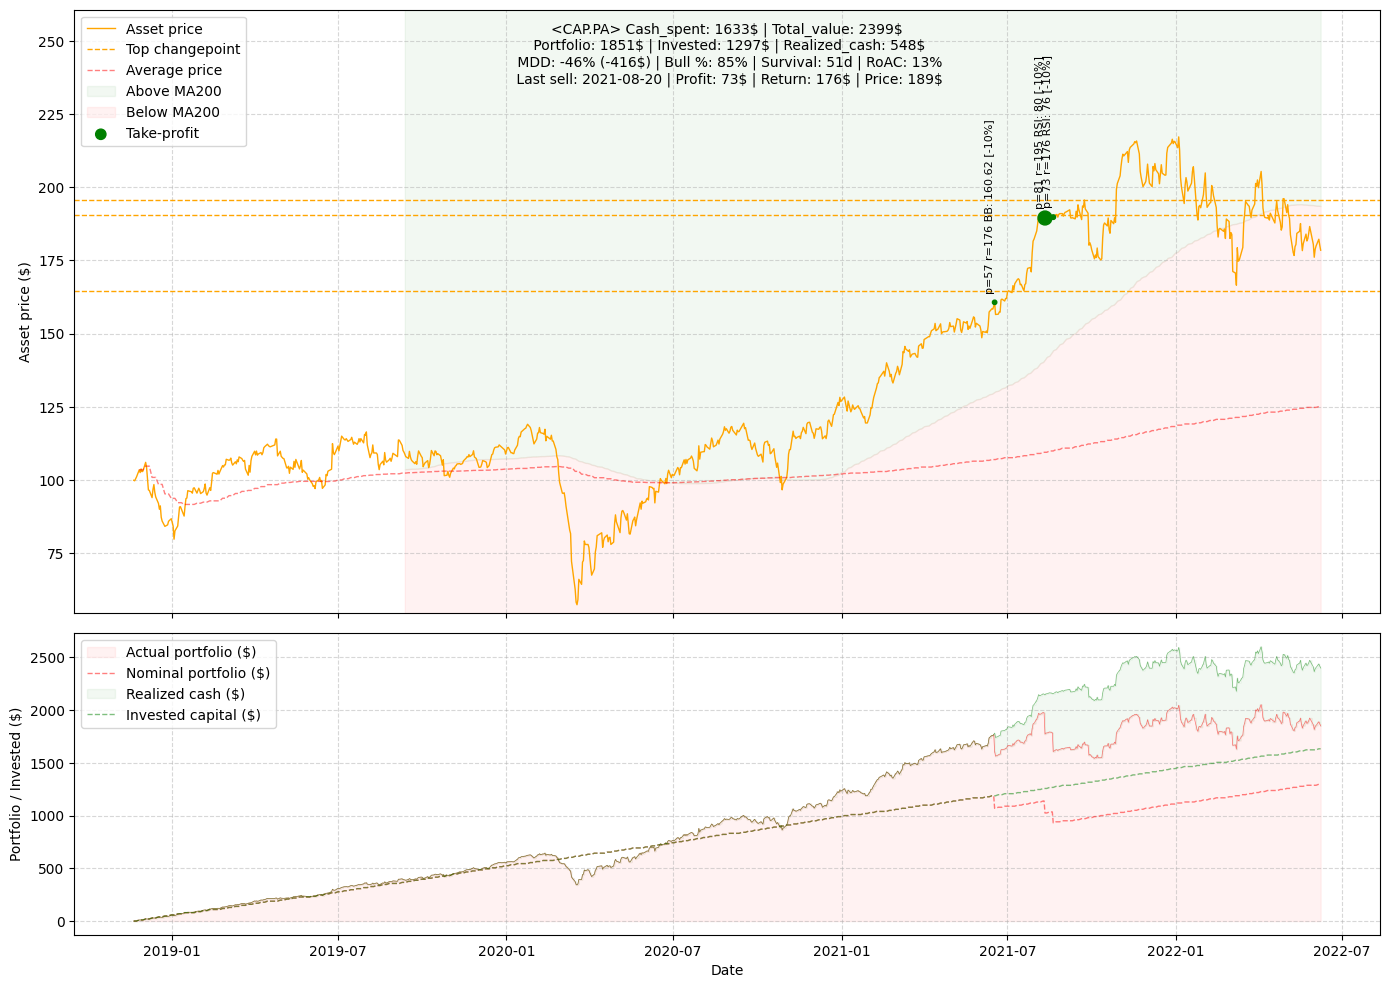

Total invested: $16452.00
Total return: $2257.00
Total value: $20216.00


In [7]:
total_invested = 0
total_profit = 0
total_return = 0
total_value = 0

for stock in random_token:
    stock_prices = prices[stock]
    stock_prices = stock_prices.dropna()

    stock_prices = stock_prices.iloc[200:]

    try:
        bt = BacktestDCA(
        target=stock,
        prices=stock_prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {stock}: {e}")
        continue

    total_invested += metrics['Cash_spent']
    total_return += metrics['Realized_cash']
    total_value += metrics['Total_value']

print(f"Total invested: ${total_invested:.2f}")
print(f"Total return: ${total_return:.2f}")
print(f"Total value: ${total_value:.2f}")

In [8]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2018-11-20,99.919998,0.000000,0.000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2018-11-21,99.760002,0.000000,0.000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2018-11-23,101.050003,0.000000,0.000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2018-11-26,103.500000,0.095652,9.900,9.9,0.0,0.0,0.000000,,9.900000,103.500000,9.900000
2018-11-27,102.550003,0.095652,9.900,9.9,0.0,0.0,0.000000,,9.809131,103.500000,9.809131
...,...,...,...,...,...,...,...,...,...,...,...
2022-06-02,178.800003,10.315794,1287.495,1623.6,0.0,0.0,548.545407,,1844.463989,124.808135,2393.009396
2022-06-03,179.949997,10.315794,1287.495,1623.6,0.0,0.0,548.545407,,1856.327089,124.808135,2404.872496
2022-06-06,182.250000,10.370115,1297.395,1633.5,0.0,0.0,548.545407,,1889.953447,125.109028,2438.498854


In [9]:
(result['Portfolio'] > 0).sum()

np.int64(882)

In [10]:
metrics

{'Target': 'CAP.PA',
 'Cash_spent': 1633,
 'Realized_cash': 548,
 'Portfolio': 1851,
 'Invested': 1297,
 'Total_value': 2399,
 'Bull_history': 85,
 'Avg_price': np.float64(125.10902804156643),
 'Num_take_profits': 3,
 'MDD': -46,
 'MDD_usd': -416,
 'MA200_survival_days': 51.0,
 'RoAC': 13}